# FarmTech Solutions — Fase 6 (Entrega 2)
## Comparação: YOLO adaptada vs YOLO padrão vs CNN do zero

**FIAP — Curso de Inteligência Artificial**

**Grupo:**
- Karina Garta Szewczuk — RM569309
- Maria Sabrina Feitosa da Silva — RM568714
- Nicolas Lima Apolinário — RM570741
- Roger Gabriel de Souza Jesus Costa — RM573659

---

Agora que já treinamos a YOLO na Entrega 1, a ideia aqui é pegar a mesma base de imagens e testar com três abordagens diferentes pra poder comparar:

- **YOLO adaptada** — o modelo que treinamos na E1, que conhece nossos objetos
- **YOLO padrão** — a YOLOv5 pré-treinada no COCO (80 classes), sem treino nenhum nosso
- **CNN do zero** — uma rede convolucional simples, construída no Keras, que classifica a imagem inteira (sem localizar o objeto)

No final monta uma tabela comparando as três em precisão, tempo de treino e tempo de inferência.

Lembrar de rodar no Colab com GPU ligada e o Drive montado.


## 1. Drive e ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
!pip install -qr requirements.txt

import torch
print('GPU:', torch.cuda.is_available())


Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (326/326), done.
remote: Compressing objects: 100% (192/192), done.
remote: Total 18770 (delta 263), reused 134 (delta 134), pack-reused 18444 (from 5)
Receiving objects: 100% (18770/18770), 17.80 MiB | 24.53 MiB/s, done.
Resolving deltas: 100% (12766/12766), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 9.7 MB/s eta 0:00:00
GPU: True


## 2. Configuração

Mesma base da E1. O `best.pt` é o modelo que salvamos no Drive no final da Entrega 1.

In [3]:
import os

BASE = '/content/drive/MyDrive/farmtech_fase6/dataset'
RAIZ = os.path.dirname(BASE)

# modelo treinado na E1
BEST_PT = f'{RAIZ}/best.pt'

CLASSE_A = 'Urso'
CLASSE_B = 'Garrafa de Café'

IMG_SIZE = 640
print('Modelo:', BEST_PT, '| existe:', os.path.exists(BEST_PT))


Modelo: /content/drive/MyDrive/farmtech_fase6/best.pt | existe: True


In [4]:
import yaml

config = {
    'train': f'{BASE}/images/train',
    'val':   f'{BASE}/images/val',
    'nc': 2,
    'names': [CLASSE_A, CLASSE_B],
}
with open('data.yaml', 'w') as f:
    yaml.dump(config, f, sort_keys=False)
print(open('data.yaml').read())


train: /content/drive/MyDrive/farmtech_fase6/dataset/images/train
val: /content/drive/MyDrive/farmtech_fase6/dataset/images/val
nc: 2
names:
- Urso
- "Garrafa de Caf\xE9"



## 3. YOLO adaptada (modelo da E1)

Rodando o nosso modelo treinado pra medir a precisão e o tempo de inferência.

In [5]:
# mAP e precision na validação
!python val.py --weights {BEST_PT} --data data.yaml --img {IMG_SIZE} --name val_adaptada


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
val: data=data.yaml, weights=['/content/drive/MyDrive/farmtech_fase6/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=val_adaptada, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
100% 22.2M/22.2M [00:00<00:00, 71.6MB/s]
val: Scanning /content/drive/MyDrive/farmtech_fase6/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 cor

In [6]:
import time

# tempo de inferência no teste
t0 = time.time()
!python detect.py --weights {BEST_PT} --source {BASE}/images/test --img {IMG_SIZE} --conf 0.25 --name det_adaptada
tempo_yolo_adaptada = time.time() - t0
print(f'\nTempo de inferência: {tempo_yolo_adaptada:.1f} s')


detect: weights=['/content/drive/MyDrive/farmtech_fase6/best.pt'], source=/content/drive/MyDrive/farmtech_fase6/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=det_adaptada, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/drive/MyDrive/farmtech_fase6/dataset/images/test/IMG_2452.jpeg: 640x384 1 Urso, 33.0ms
image 2/8 /content/drive/MyDrive/farmtech_fase6/dataset/images/test/IMG_2453.jpeg: 640x384 1 Urso, 11.2ms
image 3/8 /content/drive/MyDrive/farmtech_fase6/dataset

## 4. YOLO padrão (COCO, sem treino nosso)

A yolov5s.pt vem treinada nas 80 classes do COCO (pessoa, carro, cachorro...). A gente roda ela nas mesmas imagens de teste, sem nenhum treino. Se nossos objetos não forem dessas 80 classes, ela não vai detectar — e é exatamente esse o ponto da comparação.

In [7]:
import time

t0 = time.time()
!python detect.py --weights yolov5s.pt --source {BASE}/images/test --img {IMG_SIZE} --conf 0.25 --name det_padrao
tempo_yolo_padrao = time.time() - t0
print(f'\nTempo de inferência: {tempo_yolo_padrao:.1f} s')


detect: weights=['yolov5s.pt'], source=/content/drive/MyDrive/farmtech_fase6/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=det_padrao, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

100% 14.1M/14.1M [00:00<00:00, 169MB/s]

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
image 1/8 /content/drive/MyDrive/farmtech_fase6/dataset/images/test/IMG_2452.jpeg: 640x384 1 teddy bear, 34.0ms
image 2/8 /content/drive/MyDrive/farmtech_fase6/dataset/images/test/IMG_2453.jpeg: 640x384 1 teddy bear, 11.6ms
image 3/8 /content/drive/MyDrive/far

In [8]:
from IPython.display import Image, display
import glob

# mostra umas detecções pra ver o que ela achou
for caminho in sorted(glob.glob('runs/detect/det_padrao/*.jpg'))[:4]:
    display(Image(filename=caminho, width=450))


Se os objetos não são do COCO, ela não detecta (ou detecta como outra coisa). É super fácil de usar, mas não serve pra objetos específicos.

## 5. CNN treinada do zero

Aqui muda a abordagem: em vez de detectar (achar onde está), a CNN classifica a imagem inteira — é classe A ou classe B. Montamos uma rede simples no Keras e treinamos com as mesmas imagens.

Primeiro precisa reorganizar as imagens em pastas por classe, porque é assim que o Keras espera.

### 5.1 Reorganizar por classe

In [9]:
import os, glob, shutil

CLASSIF = '/content/classificacao'
classes = {0: CLASSE_A, 1: CLASSE_B}

def organiza(split):
    for img in glob.glob(f'{BASE}/images/{split}/*'):
        nome = os.path.splitext(os.path.basename(img))[0]
        rotulo = f'{BASE}/labels/{split}/{nome}.txt'
        if not os.path.exists(rotulo):
            continue
        with open(rotulo) as f:
            linha = f.readline().split()
        if not linha:
            continue
        cls_id = int(linha[0])
        dest = f'{CLASSIF}/{split}/{classes[cls_id]}'
        os.makedirs(dest, exist_ok=True)
        shutil.copy(img, dest)

for split in ['train', 'val']:
    organiza(split)

for split in ['train', 'val']:
    for c in classes.values():
        pasta = f'{CLASSIF}/{split}/{c}'
        qtd = len(glob.glob(f'{pasta}/*')) if os.path.exists(pasta) else 0
        print(f'{split}/{c}: {qtd}')


train/Urso: 32
train/Garrafa de Café: 32
val/Urso: 4
val/Garrafa de Café: 4


### 5.2 Montar a CNN

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG = (160, 160)
BATCH = 8

train_ds = tf.keras.utils.image_dataset_from_directory(
    f'{CLASSIF}/train', image_size=IMG, batch_size=BATCH, label_mode='binary')
val_ds = tf.keras.utils.image_dataset_from_directory(
    f'{CLASSIF}/val', image_size=IMG, batch_size=BATCH, label_mode='binary')

print('Classes:', train_ds.class_names)


Found 64 files belonging to 2 classes.
Found 8 files belonging to 2 classes.
Classes: ['Garrafa de Café', 'Urso']


In [11]:
# data augmentation pra base pequena
aug = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# 3 blocos de convolução + classificador binário
cnn = models.Sequential([
    layers.Input((160, 160, 3)),
    aug,
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,327,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,350,817 (5.15 MB)

 Trainable params: 1,350,817 (5.15 MB)

 Non-trainable params: 0 (0.00 B)

### 5.3 Treinar

In [12]:
import time

t0 = time.time()
hist = cnn.fit(train_ds, validation_data=val_ds, epochs=20)
tempo_treino_cnn = time.time() - t0
print(f'\nTempo de treino: {tempo_treino_cnn:.1f} s')


Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 15s 878ms/step - accuracy: 0.5938 - loss: 0.8772 - val_accuracy: 0.5000 - val_loss: 0.8089
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.5000 - loss: 0.6995 - val_accuracy: 0.5000 - val_loss: 0.6948
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.5000 - loss: 0.6970 - val_accuracy: 0.5000 - val_loss: 0.6951
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.5469 - loss: 0.6899 - val_accuracy: 0.5000 - val_loss: 0.6962
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5938 - loss: 0.6860 - val_accuracy: 0.3750 - val_loss: 0.7053
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6562 - loss: 0.6831 - val_accuracy: 0.5000 - val_loss: 0.7164
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.5469 - loss: 0.6840 - val_accuracy: 0.3750 - val_loss: 0.7199
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6406 - loss: 0.6529 - val_accuracy: 0.1250 - val_loss: 0.8347
Epoch 

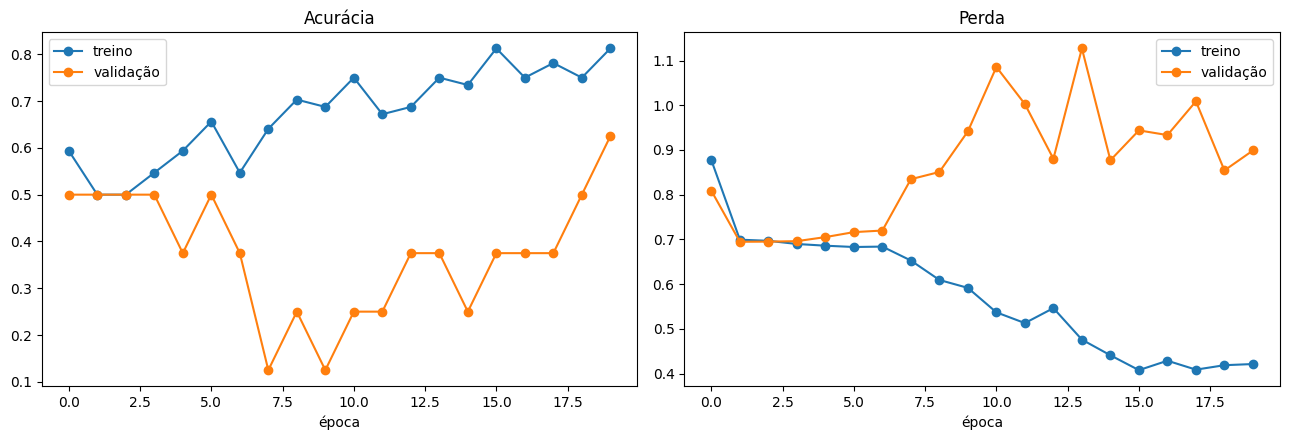

Acurácia na validação: 62.50%


In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.history['accuracy'], marker='o', label='treino')
axes[0].plot(hist.history['val_accuracy'], marker='o', label='validação')
axes[0].set_title('Acurácia'); axes[0].set_xlabel('época'); axes[0].legend()

axes[1].plot(hist.history['loss'], marker='o', label='treino')
axes[1].plot(hist.history['val_loss'], marker='o', label='validação')
axes[1].set_title('Perda'); axes[1].set_xlabel('época'); axes[1].legend()

plt.tight_layout()
plt.savefig('/content/cnn_curvas.png', dpi=120)
plt.show()

acc_cnn = hist.history['val_accuracy'][-1]
print(f'Acurácia na validação: {acc_cnn:.2%}')


In [14]:
import time, numpy as np

# tempo de inferência por imagem
for imgs, _ in val_ds.take(1):
    t0 = time.time()
    _ = cnn.predict(imgs, verbose=0)
    tempo_inf_cnn = (time.time() - t0) / len(imgs)
print(f'Inferência: {tempo_inf_cnn*1000:.1f} ms por imagem')


Inferência: 19.8 ms por imagem


Com só 64 imagens de treino é normal a CNN ter dificuldade. Se a acurácia de treino fica alta mas a de validação oscila, é overfitting — faz sentido, porque sem transfer learning a rede precisa de muito mais dado pra aprender.

## 6. Comparação das três abordagens

| Critério | YOLO adaptada | YOLO padrão | CNN do zero |
|---|---|---|---|
| O que faz | detecta e localiza nossos objetos | detecta 80 classes genéricas | classifica a imagem inteira |
| Facilidade | média (rotular + treinar) | alta (zero treino) | média/baixa (montar a rede) |
| Precisão | mAP@0.5 = 0.995 (99.5%) | não detectou nossos objetos (classificou como "teddy bear" e "vase") | acurácia de validação = 62.50% |
| Tempo de treino | ~10-20 min (na E1) | zero | 207.6 s (~3.5 min) |
| Tempo de inferência | ~14.8 ms/imagem | ~14.4 ms/imagem | 19.8 ms/imagem |

**Análise:**

A **YOLO padrão** é a mais fácil de usar, mas só serve se os objetos forem do COCO — pro nosso caso não funcionou. Ela classificou os ursos como "teddy bear" e as garrafas de café como "vase", mostrando que sem treino customizado ela não reconhece objetos específicos.

A **YOLO adaptada** é a melhor opção: combina transfer learning com detecção precisa dos nossos objetos específicos (mAP 99.5%), localiza o objeto na imagem com bounding box e teve tempo de inferência baixo (~14.8ms).

A **CNN do zero** teve dificuldade com a base pequena (64 imagens de treino): a acurácia de validação ficou em apenas 62.50%, com sinais claros de overfitting (acurácia de treino subindo enquanto a de validação oscila). Sem transfer learning, a rede precisa de muito mais dados pra aprender. Além disso, a CNN só classifica — não localiza o objeto na imagem.

**Conclusão:** pra detecção de objetos específicos com base pequena, o transfer learning com YOLO é a melhor estratégia. A CNN do zero é útil pra entender como a rede funciona por dentro, mas pra aplicação prática o YOLO adaptado ganha em todos os critérios.
